In [ ]:
# Monte Carlo LCOH distributions: style, data and summary statistics
import json
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scienceplots  # noqa: F401  (registers the "science" styles)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import AutoMinorLocator, MaxNLocator, MultipleLocator

# ---------------------------------------------------------------------------
# Plot style
# ---------------------------------------------------------------------------
TICK_FONT = 21.0
AXIS_LABEL_FONT = 23.0
LEGEND_FONT = 20.0

plt.style.use(["science", "ieee"])
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Times"],
    "font.size": TICK_FONT,
    "axes.labelsize": AXIS_LABEL_FONT,
    "xtick.labelsize": TICK_FONT,
    "ytick.labelsize": TICK_FONT,
    "legend.fontsize": LEGEND_FONT,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.grid": False,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
SMR_COLORS = {"band": "#AFCDEB", "text": "#1976D2"}
ELECTROLYSIS_COLORS = {"band": "#B4D8B4", "text": "#2E7D32"}

# Each technology: legend name, histogram fill and line colours, and its
# Monte Carlo results file (relative to the project root)
TECHNOLOGIES = {
    "SMR": {"name": "SMR", "fill": SMR_COLORS["band"], "line": SMR_COLORS["text"],
            "file": "SMR/LCOH_MonteCarlo_SMR.json"},
    "WE":  {"name": "Water electrolysis", "fill": ELECTROLYSIS_COLORS["band"], "line": ELECTROLYSIS_COLORS["text"],
            "file": "WaterElectrolysis/LCOH_MonteCarlo_WE.json"},
    "Ni":  {"name": "Nickel", "fill": "#E69F00", "line": "#E69F00",
            "file": "NiMP/Results_TEA/LCOH_MonteCarlo.json"},
    "Fe":  {"name": "Iron", "fill": "#7B4AB5", "line": "#7B4AB5",
            "file": "FeMP/Results_TEA/LCOH_MonteCarlo.json"},
    "AC":  {"name": "Activated carbon", "fill": "#D62728", "line": "#D62728",
            "file": "ACMP/Results_TEA/LCOH_MonteCarlo.json"},
}

# Literature LCOH ranges [US$/kg], drawn as vertical bands with a label on top
REFERENCE_BANDS = {
    "SMR":          {"range": (2.2, 3.3), **SMR_COLORS},
    "Electrolysis": {"range": (4.8, 8.5), **ELECTROLYSIS_COLORS},
}

NUM_BINS = 60             # bins of the input-distribution histograms
BIN_WIDTH = 1.0           # default LCOH histogram bin width [US$/kg]
BIN_WIDTHS = {"Ni": 0.5, "Fe": 0.5}  # finer bins for the narrower catalyst distributions
X_MIN, X_MAX = -5, 45     # LCOH axis limits [US$/kg]; the share of samples outside them is noted
HIST_ALPHA = 0.25
FIG_SIZE = (16, 8.5)
PANEL_WIDTH_RATIOS = (2.3, 1)  # density panel (main) : cumulative panel
PANEL_LETTER_GAP = 8      # gap [pt] between an x-axis label and the panel letter below it
LCOH_LABEL = r"LCOH / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]"


# ---------------------------------------------------------------------------
# Load data
# ---------------------------------------------------------------------------
def find_project_root(required_folders):
    """Walk up from this file (or the CWD) until a folder containing all
    ``required_folders`` is found."""
    try:
        start_dir = Path(__file__).resolve().parent
    except NameError:  # running inside a notebook
        start_dir = Path.cwd()

    for candidate in [start_dir, *start_dir.parents]:
        if all((candidate / folder).is_dir() for folder in required_folders):
            return candidate
    raise FileNotFoundError("Project root not found.")


def load_lcoh_samples(results_file):
    """Monte Carlo LCOH samples [US$/kg] stored under metrics -> LCOP."""
    with open(results_file, "r") as f:
        samples = np.asarray(json.load(f)["metrics"]["LCOP"], dtype=float)

    if samples.size < 2 or not np.all(np.isfinite(samples)):
        raise ValueError(f"Invalid Monte Carlo samples in {results_file}")
    return samples


project_root = find_project_root(["FeMP", "ACMP", "NiMP", "SMR", "WaterElectrolysis"])

for key, tech in TECHNOLOGIES.items():
    tech["samples"] = load_lcoh_samples(project_root / tech["file"])
    tech["mu"] = np.mean(tech["samples"])
    tech["sigma"] = np.std(tech["samples"])
    if tech["sigma"] <= 0:
        raise ValueError(f"Zero standard deviation for {key}.")

# ---------------------------------------------------------------------------
# Summary statistics [US$/kg]
# ---------------------------------------------------------------------------
electrolysis_max = REFERENCE_BANDS["Electrolysis"]["range"][1]
print(f"{'Technology':<20}{'Mean':>8}{'Median':>8}{'P5':>8}{'P95':>8}{'P(<=0)':>9}"
      f"{f'P(<{electrolysis_max:g})':>10}")
for tech in TECHNOLOGIES.values():
    samples = tech["samples"]
    p5, p50, p95 = np.percentile(samples, [5, 50, 95])
    print(f"{tech['name']:<20}{tech['mu']:>8.2f}{p50:>8.2f}{p5:>8.2f}{p95:>8.2f}"
          f"{np.mean(samples <= 0) * 100:>8.1f}%{np.mean(samples < electrolysis_max) * 100:>9.1f}%")

Technology              Mean  Median      P5     P95   P(<=0)   P(<8.5)
SMR                     6.86    6.74    4.24    9.91     0.0%     82.3%
Water electrolysis      7.59    7.49    4.78   10.77     0.0%     70.4%
Nickel                  8.69    8.73    4.02   13.16     0.5%     46.2%
Iron                   15.41   15.45    9.25   21.44     0.0%      3.3%
Activated carbon       24.87   25.70    2.15   44.69     3.8%     10.7%


In [ ]:
# Plotting function shared by both LCOH figures
def style_axes(ax):
    """Inward ticks on all four sides and black spines."""
    ax.tick_params(axis="both", which="major", direction="in", top=True, bottom=True,
                   left=True, right=True, length=8, width=1.2, labelsize=TICK_FONT,
                   colors="black")
    ax.tick_params(axis="both", which="minor", direction="in", top=True, bottom=True,
                   left=True, right=True, length=4, width=1.0, colors="black")
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.2)


def add_panel_letter(ax, letter, fontsize):
    """Panel letter centred PANEL_LETTER_GAP points below the x-axis label."""
    ax.annotate(letter, xy=(0.5, 0.0), xycoords=ax.xaxis.label,
                xytext=(0, -PANEL_LETTER_GAP), textcoords="offset points",
                ha="center", va="top", fontsize=fontsize)


PER_KG_H2 = r"/kg$_{\mathrm{H_2}}$"


def outside_note(tech, x_min, x_max):
    """e.g. 'Activated carbon: 1.9% below -$5/kg_H2 and 4.7% above $45/kg_H2' (None if negligible)."""
    below, above = np.mean(tech["samples"] < x_min), np.mean(tech["samples"] > x_max)
    parts = []
    if below >= 0.001:
        parts.append(f"{below * 100:.1f}% below -${abs(x_min):g}/kg_H2")
    if above >= 0.001:
        parts.append(f"{above * 100:.1f}% above ${x_max:g}/kg_H2")
    return f"{tech['name']}: " + " and ".join(parts) if parts else None


def plot_lcoh_distributions(keys, output_file, reference_bands=None, dpi=None):
    """Monte Carlo LCOH of each technology in ``keys``.

    (a) main panel, probability density: histogram bars with a solid outline
    (b) narrower panel, cumulative probability P(LCOH <= x)
    One colour legend for both panels sits above them; the median and 5-95 %
    range of each technology are listed inside (a). The x-axis is cut at
    [X_MIN, X_MAX] and the share of samples outside it is printed. Optional
    literature ranges are drawn as vertical bands.
    """
    techs = [TECHNOLOGIES[key] for key in keys]
    reference_bands = reference_bands or {}

    # Bins span all samples, so each density integrates to 1 even though the
    # x-axis is cut; bin width per technology (BIN_WIDTHS, else BIN_WIDTH)
    all_samples = np.concatenate([tech["samples"] for tech in techs])
    lowest, highest = np.floor(all_samples.min()), np.ceil(all_samples.max())

    fig, (ax_pdf, ax_cdf) = plt.subplots(1, 2, figsize=FIG_SIZE,
                                         gridspec_kw={"width_ratios": PANEL_WIDTH_RATIOS})

    for ax in (ax_pdf, ax_cdf):
        for band in reference_bands.values():
            ax.axvspan(*band["range"], facecolor=band["band"], alpha=0.70, edgecolor="none", zorder=0)
        ax.axvline(0, color="0.45", linewidth=0.9, linestyle=":", zorder=1)

    color_handles, color_labels, stat_labels, notes = [], [], [], []
    y_max = 0.0
    for key, tech in zip(keys, techs):
        samples, color = tech["samples"], tech["line"]
        width = BIN_WIDTHS.get(key, BIN_WIDTH)
        bins = np.arange(lowest, highest + width, width)

        # (a) density: bars show the bins, the outline keeps each technology distinct
        density, _, _ = ax_pdf.hist(samples, bins=bins, density=True, color=color, alpha=HIST_ALPHA,
                                    edgecolor="white", linewidth=0.5, zorder=2)
        ax_pdf.stairs(density, bins, color=color, linewidth=1.5, linestyle="-", zorder=3)
        y_max = max(y_max, density.max())

        # (b) cumulative probability
        sorted_samples = np.sort(samples)
        ax_cdf.plot(sorted_samples, np.arange(1, sorted_samples.size + 1) / sorted_samples.size,
                    color=color, linewidth=3.2, linestyle="-", zorder=3)

        p5, p50, p95 = np.percentile(samples, [5, 50, 95])
        color_handles.append(Patch(facecolor=color, alpha=HIST_ALPHA + 0.15, edgecolor=color, linewidth=1.5))
        color_labels.append(tech["name"])
        stat_labels.append(rf"{key}: & {p50:.1f} & {p5:.1f} & {p95:.1f}")  # columns of the median table
        note = outside_note(tech, X_MIN, X_MAX)
        if note:
            notes.append(note)

    for name, band in reference_bands.items():
        color_handles.append(Patch(facecolor=band["band"], alpha=0.70, edgecolor="none"))
        color_labels.append(name)

    # Axes
    ax_pdf.set_ylabel("Probability density", fontsize=AXIS_LABEL_FONT, labelpad=10)
    ax_pdf.set_ylim(0, y_max * 1.08)
    ax_pdf.yaxis.set_major_locator(MaxNLocator(nbins=6))
    ax_pdf.yaxis.set_minor_locator(AutoMinorLocator(5))
    ax_pdf.xaxis.set_major_locator(MultipleLocator(5))
    ax_pdf.xaxis.set_minor_locator(MultipleLocator(1))

    ax_cdf.set_ylabel("Cumulative probability", fontsize=AXIS_LABEL_FONT, labelpad=10)
    ax_cdf.set_ylim(0, 1.0)
    ax_cdf.yaxis.set_major_locator(MultipleLocator(0.2))
    ax_cdf.yaxis.set_minor_locator(MultipleLocator(0.05))
    ax_cdf.xaxis.set_major_locator(MultipleLocator(10))
    ax_cdf.xaxis.set_minor_locator(MultipleLocator(2.5))

    # Panel letter centred under each x-axis label
    for letter, ax in zip(("(a)", "(b)"), (ax_pdf, ax_cdf)):
        ax.set_xlabel(LCOH_LABEL, fontsize=AXIS_LABEL_FONT, labelpad=10)
        add_panel_letter(ax, letter, AXIS_LABEL_FONT)
        ax.set_xlim(X_MIN, X_MAX)
        style_axes(ax)

    # Median and 5-95 % range inside (a), as a LaTeX table so names, medians and
    # both ends of the range line up in columns
    stats_title = r"\underline{Median (P$_{5}$--P$_{95}$) / [US\$\,$\cdot$\,kg$_{\mathrm{H_2}}^{\mbox{-}1}$]}"
    stats_rows = r"\begin{tabular}{@{}l@{\ }r@{\ (}r@{--}r@{)}}" + r" \\ ".join(stat_labels) + r"\end{tabular}"
    ax_pdf.text(0.975, 0.965, r"\renewcommand{\arraystretch}{1.25}\begin{tabular}{@{}c@{}}"
                + stats_title + r" \\[2pt] " + stats_rows + r"\end{tabular}",
                transform=ax_pdf.transAxes, ha="right", va="top", fontsize=LEGEND_FONT)

    # Shared colour legend across the top
    fig.legend(color_handles, color_labels, loc="upper center", ncol=len(color_handles),
               frameon=False, fontsize=LEGEND_FONT + 1, handlelength=1.6, columnspacing=1.6,
               bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.935))  # top 6.5 % of the figure holds the shared legend

    fig.savefig(output_file, format="pdf", **({"dpi": dpi} if dpi else {}))
    plt.show()

    # Share of samples outside the x-axis
    for note in notes:
        print(note)
    return fig, (ax_pdf, ax_cdf)

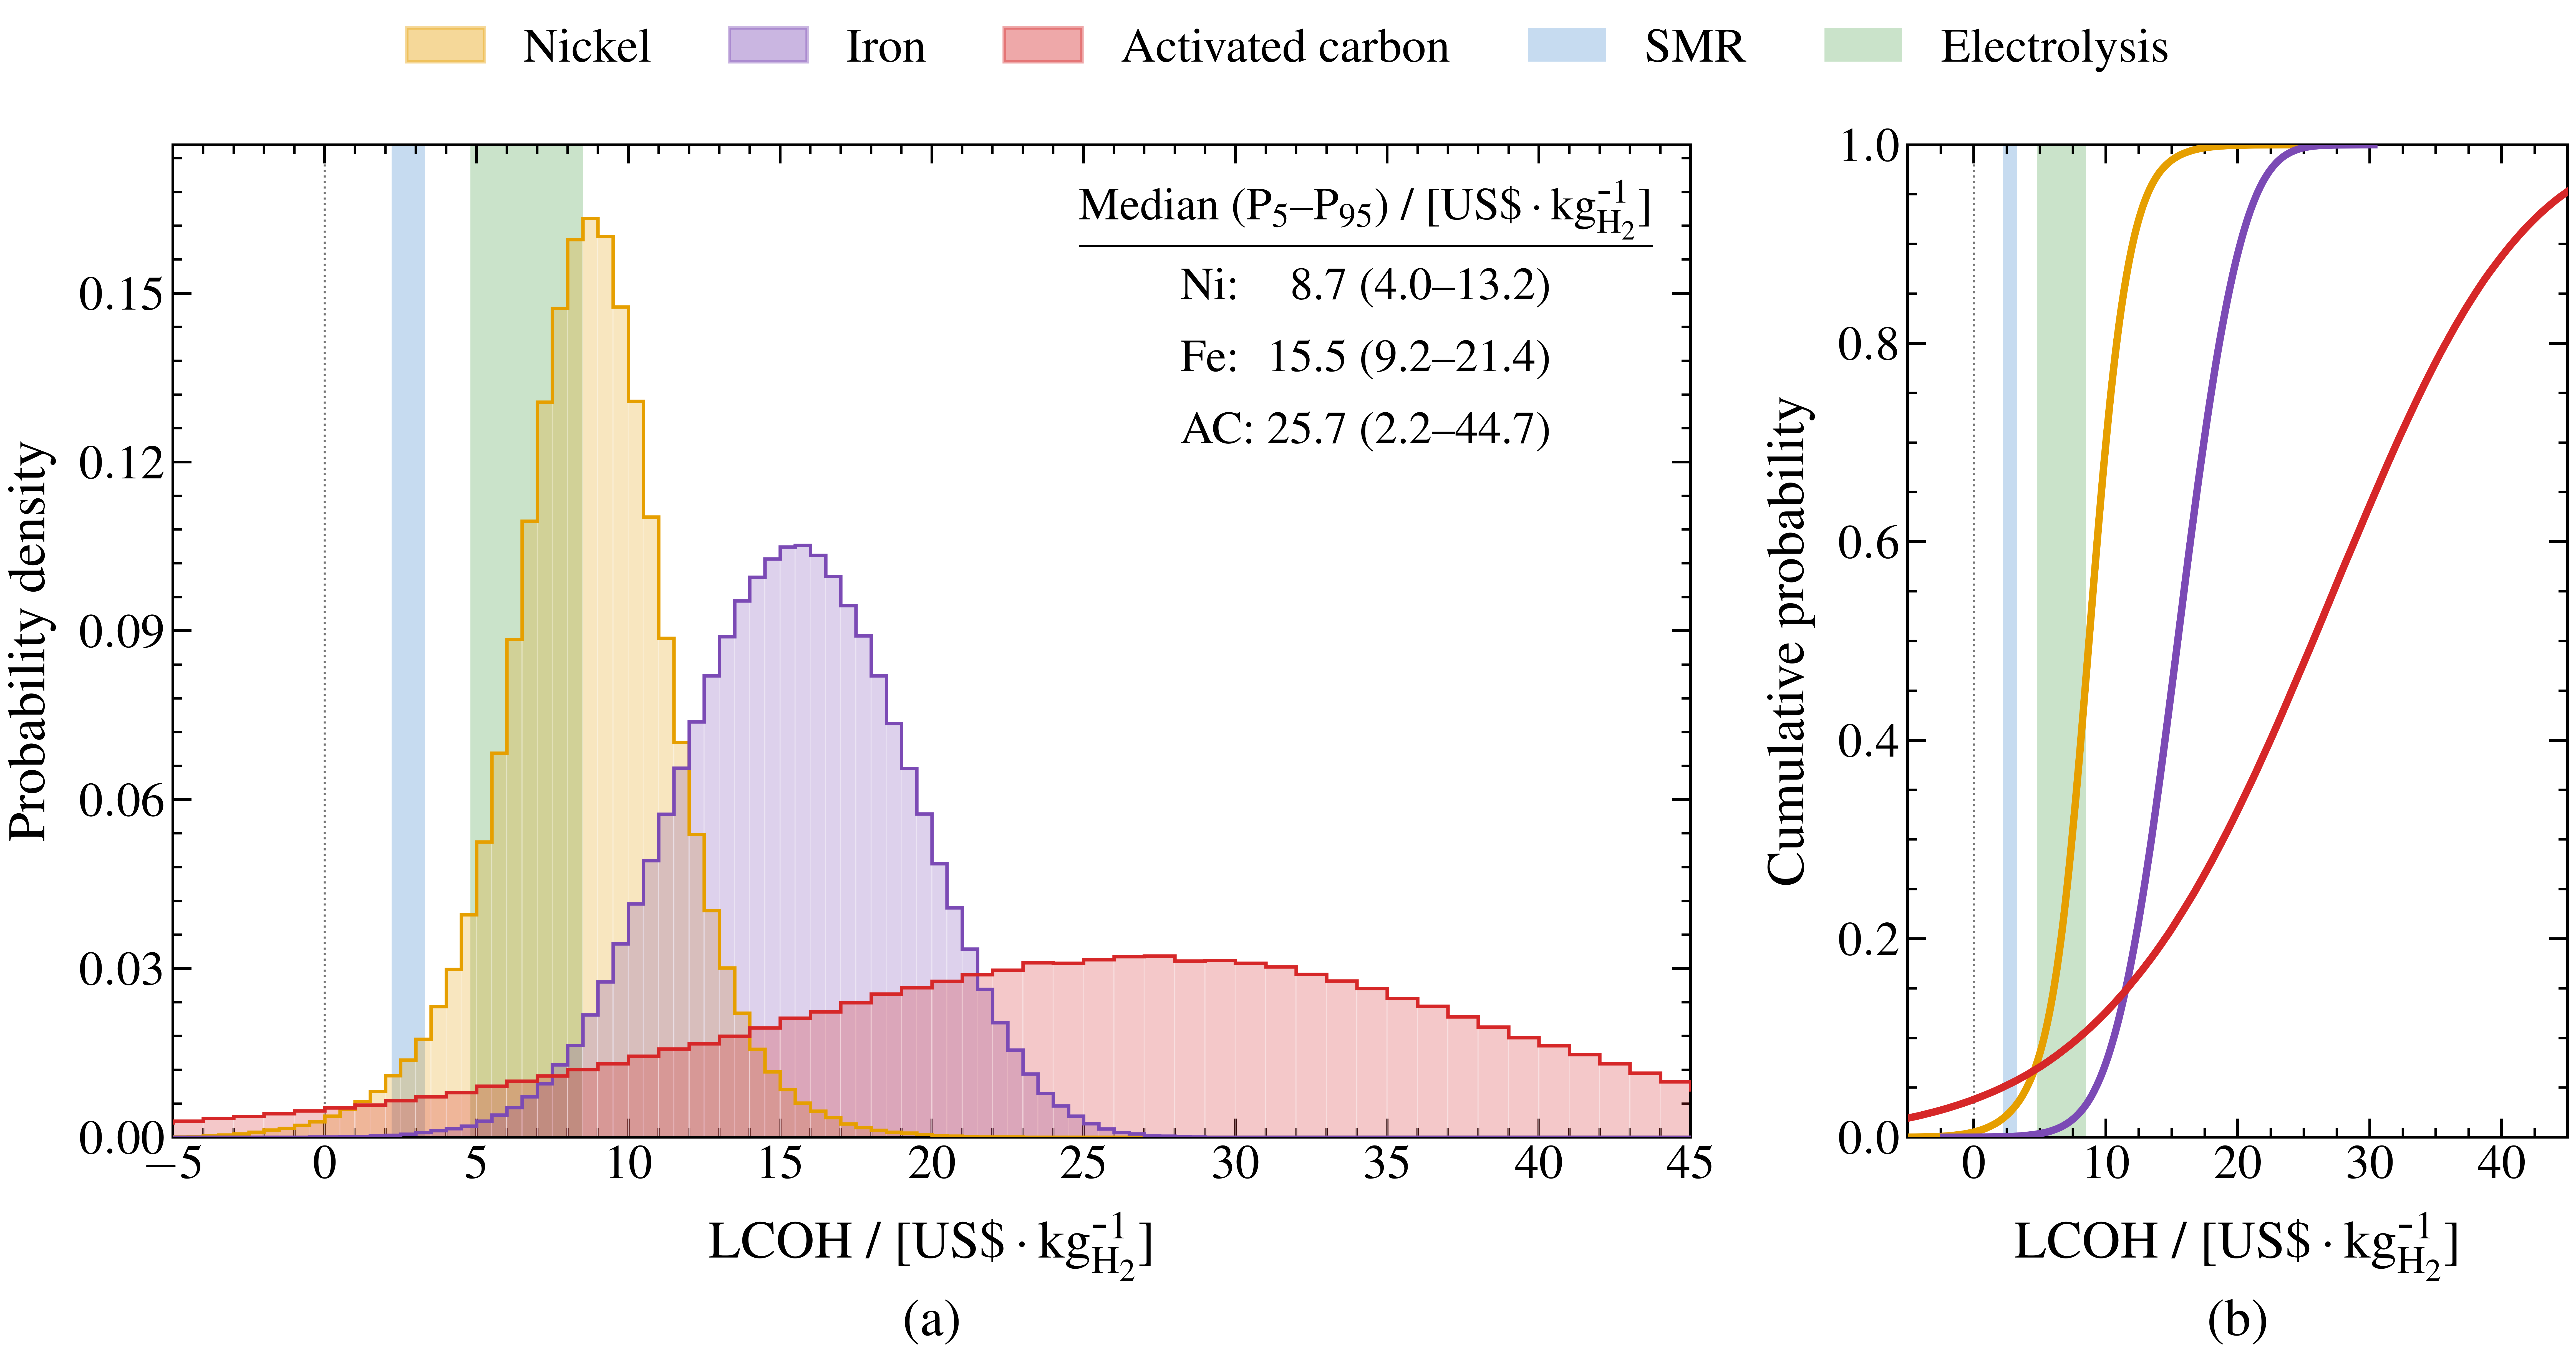

Activated carbon: 1.9% below -$5/kg_H2 and 4.7% above $45/kg_H2


In [ ]:
# Figure: methane pyrolysis catalysts, with the literature ranges of SMR and electrolysis
plot_lcoh_distributions(["Ni", "Fe", "AC"], "figure-6.pdf",
                        reference_bands=REFERENCE_BANDS, dpi=500);

In [ ]:
# Figure: all hydrogen technologies (SMR and water electrolysis from their own Monte Carlo)
# plot_lcoh_distributions(["SMR", "WE", "Ni", "Fe", "AC"], "monte_carlo_all_technologies.pdf");

In [ ]:
# Figure: sampled distributions of the carbon-related Monte Carlo inputs
# (stored under "inputs" in each catalyst's LCOH_MonteCarlo.json)
from matplotlib.ticker import FuncFormatter, ScalarFormatter


class NoZeroFormatter(ScalarFormatter):
    """Default tick labels, except the one at 0 (it crowds the y-axis 0 in the corner)."""
    def __call__(self, value, pos=None):
        return "" if abs(value) < 1e-9 else super().__call__(value, pos)

INPUT_LABELS = {
    "Carbon selling price [US$/kg]": r"Carbon selling price / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]",
    "Carbon disposal fee [US$/kg]":  r"Carbon disposal fee / [US\$\,$\cdot$\,kg$^{\mbox{-}1}$]",
    "Carbon fraction sold [-]":      r"Carbon fraction sold / [-]",
    "Separation efficiency [-]":     r"Separation efficiency / [-]",
    "Separation cost [US$/kg]":      r"Separation cost / [US\$\,$\cdot$\,kg$_{\mathrm{cat}}^{\mbox{-}1}$]",
}
CATALYST_KEYS = ["Ni", "Fe", "AC"]

for key in CATALYST_KEYS:
    with open(project_root / TECHNOLOGIES[key]["file"], "r") as f:
        stored_inputs = json.load(f).get("inputs", {})
    TECHNOLOGIES[key]["inputs"] = {name: np.asarray(values, dtype=float)
                                   for name, values in stored_inputs.items()}

# Layout: three panels on top, two centred below (each panel spans two of six grid columns)
fig = plt.figure(figsize=(16, 9.5))
grid = fig.add_gridspec(2, 6)
axes = [fig.add_subplot(grid[0, 0:2]), fig.add_subplot(grid[0, 2:4]), fig.add_subplot(grid[0, 4:6]),
        fig.add_subplot(grid[1, 1:3]), fig.add_subplot(grid[1, 3:5])]

for letter, ax, (name, xlabel) in zip("abcde", axes, INPUT_LABELS.items()):
    keys = [key for key in CATALYST_KEYS if name in TECHNOLOGIES[key]["inputs"]]
    if not keys:
        ax.axis("off")
        continue

    samples = [TECHNOLOGIES[key]["inputs"][name] for key in keys]
    bins = np.linspace(min(s.min() for s in samples), max(s.max() for s in samples), NUM_BINS + 1)

    for key, values in zip(keys, samples):
        tech = TECHNOLOGIES[key]
        ax.hist(values, bins=bins, density=True, color=tech["fill"], alpha=0.34, zorder=2)
        ax.hist(values, bins=bins, density=True, histtype="step", color=tech["line"],
                linestyle="-", linewidth=1.6, zorder=3)

    # Panel letter centred under the x-axis label
    ax.set_xlabel(xlabel, fontsize=AXIS_LABEL_FONT - 1)
    add_panel_letter(ax, f"({letter})", AXIS_LABEL_FONT - 1)
    ax.set_ylim(bottom=0)
    style_axes(ax)

# (b), (c): hide the "0" x tick label, which crowds the y-axis "0" in the corner
for ax in (axes[1], axes[2]):
    ax.xaxis.set_major_formatter(NoZeroFormatter())

# (e) Separation cost: hide the "0.0" x tick label, which crowds the y-axis "0.0"
axes[4].xaxis.set_major_formatter(FuncFormatter(lambda value, _: "" if abs(value) < 1e-9 else f"{value:.1f}"))

# Shared legend in one row at the top
fig.legend(
    [Patch(facecolor=TECHNOLOGIES[key]["fill"], alpha=0.34, edgecolor=TECHNOLOGIES[key]["line"], linewidth=1.6)
     for key in CATALYST_KEYS],
    [TECHNOLOGIES[key]["name"] for key in CATALYST_KEYS],
    loc="upper center", ncol=len(CATALYST_KEYS), frameon=False, fontsize=LEGEND_FONT + 1,
    handlelength=1.6, columnspacing=1.6, bbox_to_anchor=(0.5, 1.0))

fig.tight_layout(rect=(0, 0, 1, 0.955))  # top 4.5 % of the figure holds the shared legend
fig.savefig("figure-7.pdf", format="pdf")
plt.show()

# Statistics of the sampled inputs
print(f"{'Input':<32}{'Catalyst':<18}{'Mean':>8}{'Std':>8}{'P5':>8}{'Median':>8}{'P95':>8}{'Min':>8}{'Max':>8}")
for name in INPUT_LABELS:
    for key in CATALYST_KEYS:
        values = TECHNOLOGIES[key]["inputs"].get(name)
        if values is None:
            continue
        p5, p50, p95 = np.percentile(values, [5, 50, 95])
        print(f"{name:<32}{TECHNOLOGIES[key]['name']:<18}{values.mean():>8.3f}{values.std():>8.3f}"
              f"{p5:>8.3f}{p50:>8.3f}{p95:>8.3f}{values.min():>8.3f}{values.max():>8.3f}")

Input                           Catalyst              Mean     Std      P5  Median     P95     Min     Max
Carbon selling price [US$/kg]   Nickel               1.499   1.000   0.553   1.172   3.646   0.500   6.000
Carbon selling price [US$/kg]   Iron                 1.499   1.000   0.553   1.172   3.646   0.500   6.000
Carbon selling price [US$/kg]   Activated carbon     1.499   0.670   0.594   1.391   2.740   0.500   3.000
Carbon disposal fee [US$/kg]    Nickel               1.000   0.712   0.298   0.775   2.538   0.250   4.000


Carbon disposal fee [US$/kg]    Iron                 0.751   0.416   0.283   0.634   1.629   0.250   2.000
Carbon disposal fee [US$/kg]    Activated carbon     0.500   0.241   0.146   0.476   0.924   0.010   1.000
Carbon fraction sold [-]        Nickel               0.500   0.174   0.166   0.524   0.746   0.000   0.922
Carbon fraction sold [-]        Iron                 0.500   0.174   0.166   0.524   0.745   0.000   0.938


Carbon fraction sold [-]        Activated carbon     0.500   0.174   0.255   0.476   0.834   0.077   1.000
Separation efficiency [-]       Iron                 0.850   0.034   0.787   0.855   0.895   0.641   0.900
Separation cost [US$/kg]        Iron                 0.615   0.317   0.164   0.580   1.189   0.100   2.481
